In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import re

In [2]:
df = pd.read_csv("/content/india_job_market_2024_2026.csv")
df_before = df.copy()

In [3]:
print("Initial shape:", df.shape)
display(df.head())
df.info()
display(df.describe(include="all"))

Initial shape: (5000, 17)


,Job_ID,Job_Title,Company,Company_Type,Industry,City,Location_Tier,Experience_Level,Job_Type,Work_Mode,Salary_LPA,Skills_Required,Education_Required,Openings,Applicants,Company_Rating,Date_Posted
0,IND2025000,Android Developer,Tech Mahindra,MNC,Information Technology,Remote,Remote,Senior (6-10 yrs),Full-Time,Remote,30.9,"Kotlin, Java, REST APIs",M.Tech/M.E.,3,276,4.0,2025-10-31
1,IND2025001,QA Engineer,Dream11,Indian Unicorn,Information Technology,Lucknow,Tier 2,Senior (6-10 yrs),Full-Time,Hybrid,58.6,"Selenium, Manual Testing, Postman, API Testing...",B.Tech/B.E.,3,325,4.0,2025-05-19
2,IND2025002,Business Analyst,HAL,PSU/Govt,EdTech,Remote,Remote,Senior (6-10 yrs),Full-Time,Remote,18.4,"JIRA, Excel, Power BI",MCA,5,559,3.6,2024-08-21
3,IND2025003,Cybersecurity Analyst,Groww,Startup,Information Technology,Mumbai,Tier 1,Mid (3-6 yrs),Full-Time,Hybrid,21.7,"Penetration Testing, Python, Ethical Hacking, ...",BCA,3,184,3.5,2026-03-18
4,IND2025004,Python Developer,Oracle,MNC,EdTech,Remote,Remote,Junior (1-3 yrs),Full-Time,Remote,8.0,"Docker, REST APIs, AWS, PostgreSQL",MCA,1,64,3.9,2024-10-25


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Job_ID              5000 non-null   object 
 1   Job_Title           5000 non-null   object 
 2   Company             5000 non-null   object 
 3   Company_Type        5000 non-null   object 
 4   Industry            5000 non-null   object 
 5   City                5000 non-null   object 
 6   Location_Tier       5000 non-null   object 
 7   Experience_Level    5000 non-null   object 
 8   Job_Type            5000 non-null   object 
 9   Work_Mode           5000 non-null   object 
 10  Salary_LPA          5000 non-null   float64
 11  Skills_Required     5000 non-null   object 
 12  Education_Required  5000 non-null   object 
 13  Openings            5000 non-null   int64  
 14  Applicants          5000 non-null   int64  
 15  Company_Rating      5000 non-null   float64
 16  Date_P

,Job_ID,Job_Title,Company,Company_Type,Industry,City,Location_Tier,Experience_Level,Job_Type,Work_Mode,Salary_LPA,Skills_Required,Education_Required,Openings,Applicants,Company_Rating,Date_Posted
count,5000,5000,5000,5000,5000,5000,5000,5000,5000,5000,5000.000000,5000,5000,5000.000000,5000.000000,5000.000000,5000
unique,5000,30,53,4,15,17,3,5,4,3,NaN,4817,8,NaN,NaN,NaN,697
top,IND2029999,Software Engineer,Wipro,MNC,Information Technology,Remote,Tier 1,Mid (3-6 yrs),Full-Time,On-Site,NaN,"Next.js, JavaScript, React",B.Tech/B.E.,NaN,NaN,NaN,2025-10-06
freq,1,336,134,1717,1545,1992,2086,1378,3648,2005,NaN,3,2000,NaN,NaN,NaN,16
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,19.829440,NaN,NaN,3.642600,302.072000,3.698420,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.136741,NaN,NaN,4.046942,363.989613,0.424994,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.800000,NaN,NaN,1.000000,14.000000,2.500000,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.800000,NaN,NaN,1.000000,99.000000,3.400000,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13.600000,NaN,NaN,2.000000,185.000000,3.800000,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,25.600000,NaN,NaN,3.000000,321.000000,4.100000,NaN


# Missing values

In [4]:
display(pd.DataFrame({"Missing":df.isna().sum(),"Percentage":(df.isna().mean()*100).round(2)}))


,Missing,Percentage
Job_ID,0,0.0
Job_Title,0,0.0
Company,0,0.0
Company_Type,0,0.0
Industry,0,0.0
City,0,0.0
Location_Tier,0,0.0
Experience_Level,0,0.0
Job_Type,0,0.0
Work_Mode,0,0.0


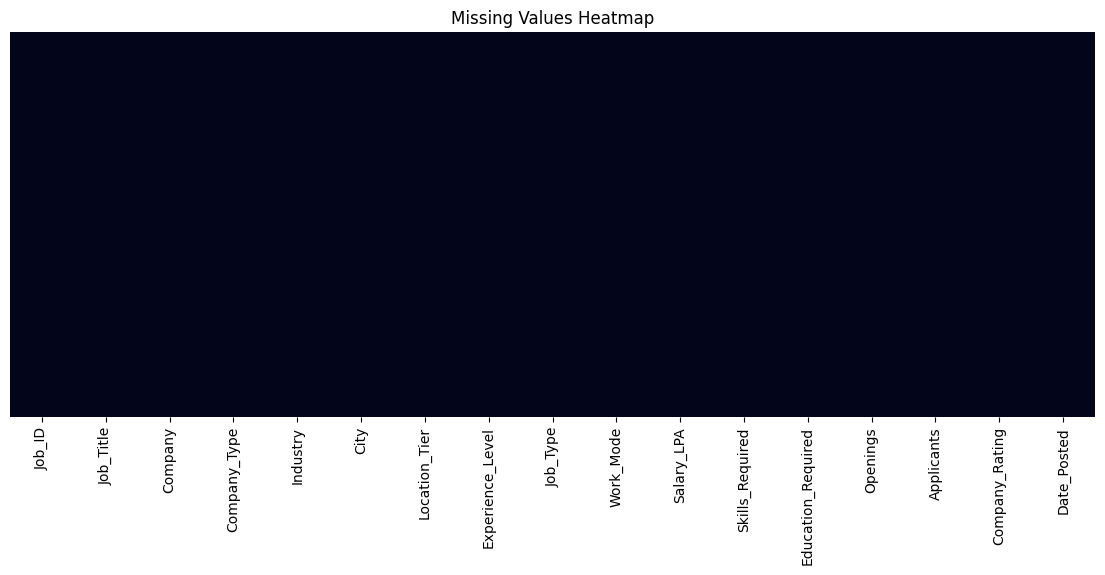

In [5]:
plt.figure(figsize=(14,5))
sns.heatmap(df.isna(), cbar=False, yticklabels=False)
plt.title("Missing Values Heatmap")
plt.show()


# Standardize columns

In [6]:
df.columns = (df.columns.str.strip().str.lower()
              .str.replace(r"[^a-z0-9]+","_",regex=True).str.strip("_"))

# Text cleaning

In [7]:
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].apply(lambda x: re.sub(r"\\s+"," ",x).strip() if isinstance(x,str) else x)

# Types

In [8]:
if "job_id" in df: df["job_id"] = df["job_id"].astype("string")
for col in ["salary_lpa","openings","applicants","company_rating"]:
    if col in df: df[col] = pd.to_numeric(df[col],errors="coerce")
if "date_posted" in df: df["date_posted"] = pd.to_datetime(df["date_posted"],errors="coerce")


# Missing values

In [9]:
for col in df.columns:
    if df[col].isna().any():
        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].fillna(df[col].median())
        elif pd.api.types.is_datetime64_any_dtype(df[col]):
            vals=df[col].dropna().sort_values()
            if len(vals): df[col]=df[col].fillna(vals.iloc[len(vals)//2])
        else:
            m=df[col].mode(dropna=True)
            df[col]=df[col].fillna(m.iloc[0] if len(m) else "Unknown")


# Duplicates

In [10]:
print("Duplicates before:", df.duplicated().sum())
df=df.drop_duplicates().reset_index(drop=True)
print("Duplicates after:", df.duplicated().sum())

Duplicates before: 0
Duplicates after: 0


# IQR

In [11]:
for col in ["salary_lpa","openings","applicants","company_rating"]:
    if col in df:
        q1,q3=df[col].quantile(.25),df[col].quantile(.75)
        iqr=q3-q1
        lo,hi=q1-1.5*iqr,q3+1.5*iqr
        df[col+"_outlier"]=(df[col]<lo)|(df[col]>hi)
        print(col, "lower:",lo,"upper:",hi,"outliers:",int(df[col+"_outlier"].sum()))


salary_lpa lower: -21.400000000000002 upper: 53.800000000000004 outliers: 354
openings lower: -2.0 upper: 6.0 outliers: 624
applicants lower: -234.0 upper: 654.0 outliers: 516
company_rating lower: 2.3500000000000005 upper: 5.1499999999999995 outliers: 0


# Boxplots

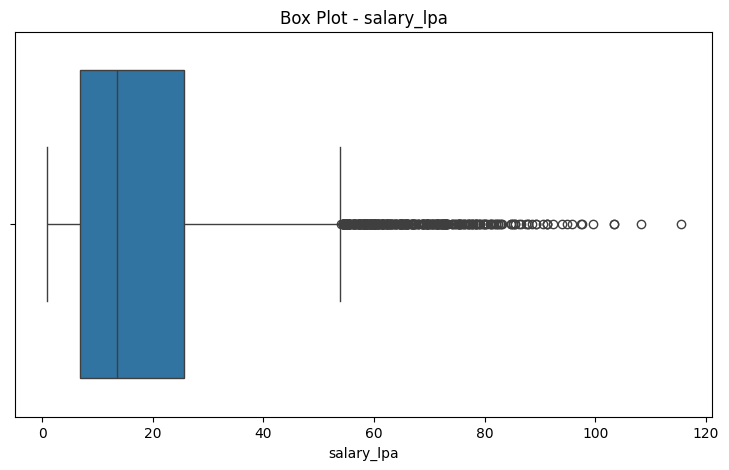

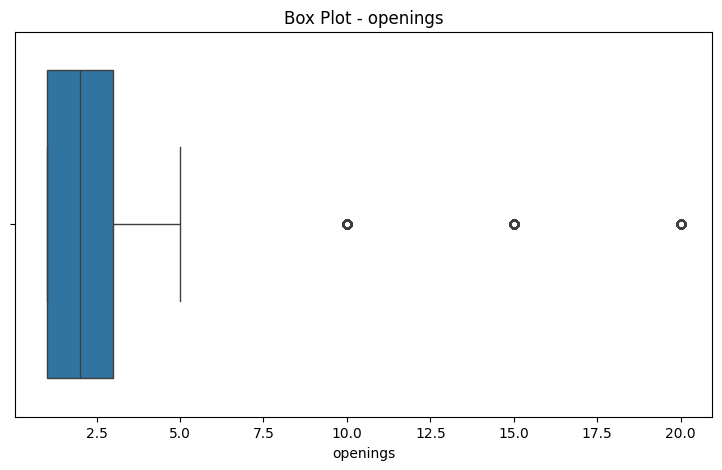

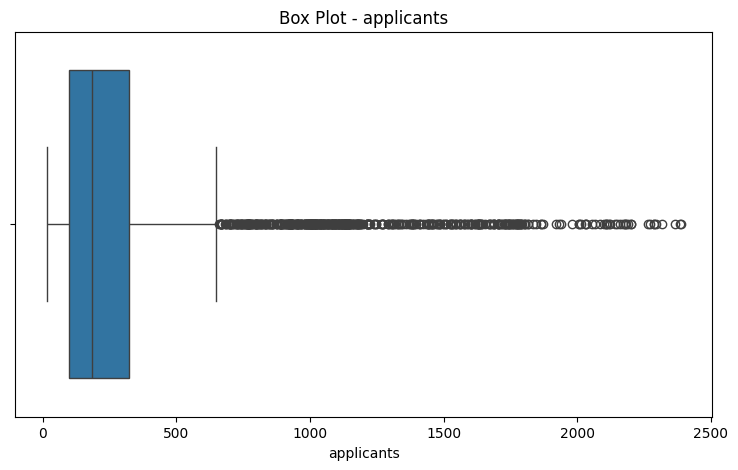

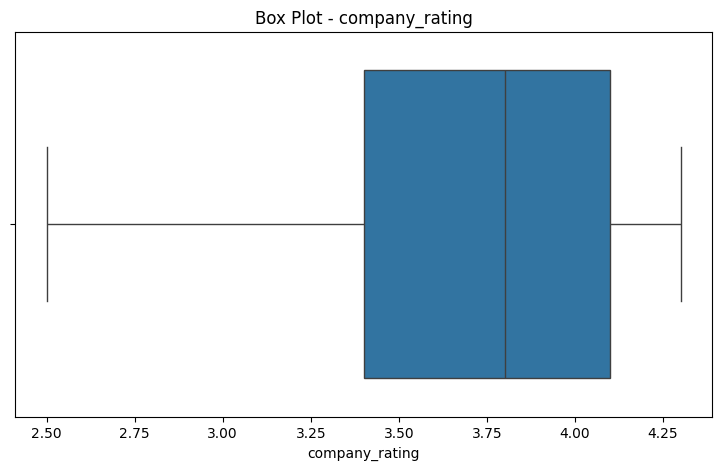

In [12]:
for col in ["salary_lpa","openings","applicants","company_rating"]:
    if col in df:
        plt.figure(figsize=(9,5))
        sns.boxplot(x=df[col])
        plt.title("Box Plot - "+col)
        plt.show()

# One-hot encoded copy

In [13]:
encoding_cols=[c for c in ["company_type","industry","location_tier","experience_level","job_type","work_mode","education_required"] if c in df]
df_encoded=pd.get_dummies(df,columns=encoding_cols,drop_first=True,dtype=int)

# Validation

In [14]:
print("Final shape:",df.shape)
print("Missing:",int(df.isna().sum().sum()))
print("Duplicates:",int(df.duplicated().sum()))
display(df.dtypes)
display(df.describe())

Final shape: (5000, 21)
Missing: 0
Duplicates: 0


,0
job_id,string[python]
job_title,object
company,object
company_type,object
industry,object
city,object
location_tier,object
experience_level,object
job_type,object
work_mode,object


,salary_lpa,openings,applicants,company_rating,date_posted
count,5000.000000,5000.000000,5000.000000,5000.000000,5000
mean,19.829440,3.642600,302.072000,3.698420,2025-05-16 11:47:54.240000
min,0.800000,1.000000,14.000000,2.500000,2024-06-01 00:00:00
25%,6.800000,1.000000,99.000000,3.400000,2024-11-19 18:00:00
50%,13.600000,2.000000,185.000000,3.800000,2025-05-16 00:00:00
75%,25.600000,3.000000,321.000000,4.100000,2025-11-03 06:00:00
max,115.400000,20.000000,2387.000000,4.300000,2026-04-30 00:00:00
std,18.136741,4.046942,363.989613,0.424994,NaN


# Export

In [17]:
df.to_csv("/content/india_job_market_2024_2026.csv",index=False)
df_encoded.to_csv("/content/india_job_market_2024_2026.csv",index=False)
print("Files exported.")

Files exported.
